# Sales Analytics and Business Insights

This notebook analyzes the warehouse output to explain what is happening in the business in a way that is easy to understand. The goal is to turn raw warehouse tables into a clear, stakeholder-friendly story using business-friendly charts and KPIs.

We use the Gold-layer tables: customer dimension, product dimension, and sales fact table.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 150

base = Path('../EDA/datasets/csv_files')
plots_dir = Path('plots')
plots_dir.mkdir(exist_ok=True)

customer = pd.read_csv(base / 'gold.dim_customers.csv')
product = pd.read_csv(base / 'gold.dim_products.csv')
fact = pd.read_csv(base / 'gold.fact_sales.csv')
customer_report = pd.read_csv(base / 'gold.report_customers.csv')
product_report = pd.read_csv(base / 'gold.report_products.csv')

fact['order_date'] = pd.to_datetime(fact['order_date'])
customer['customer_key'] = customer['customer_key'].astype(int)
product['product_key'] = product['product_key'].astype(int)

print('Customers:', customer.shape[0])
print('Products:', product.shape[0])
print('Sales rows:', fact.shape[0])
print('Date range:', fact['order_date'].min().date(), 'to', fact['order_date'].max().date())

Customers: 18484
Products: 295
Sales rows: 60398
Date range: 2010-12-29 to 2014-01-28


## 1. Key performance metrics

This summary gives a quick overview of business performance before we look at trends and segments.

In [2]:
sales_total = fact['sales_amount'].sum()
qty_total = fact['quantity'].sum()
orders_total = fact['order_number'].nunique()
customers_total = fact['customer_key'].nunique()
products_total = fact['product_key'].nunique()
avg_order_value = fact.groupby('order_number')['sales_amount'].sum().mean()

kpi_df = pd.DataFrame({
    'Metric': ['Total Sales', 'Total Quantity Sold', 'Total Orders', 'Unique Customers', 'Unique Products Sold', 'Average Order Value'],
    'Value': [sales_total, qty_total, orders_total, customers_total, products_total, avg_order_value]
})

kpi_df

print(kpi_df.to_string(index=False))

              Metric        Value
         Total Sales 2.935625e+07
 Total Quantity Sold 6.042300e+04
        Total Orders 2.765900e+04
    Unique Customers 1.848400e+04
Unique Products Sold 1.300000e+02
 Average Order Value 1.061363e+03


## 2. Which countries contribute the most revenue?

This chart helps identify where the business is winning and where the biggest opportunities are.

/tmp/ipykernel_1754560/456671820.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bar = sns.barplot(data=country_revenue, x='sales_amount', y='country', palette='viridis')


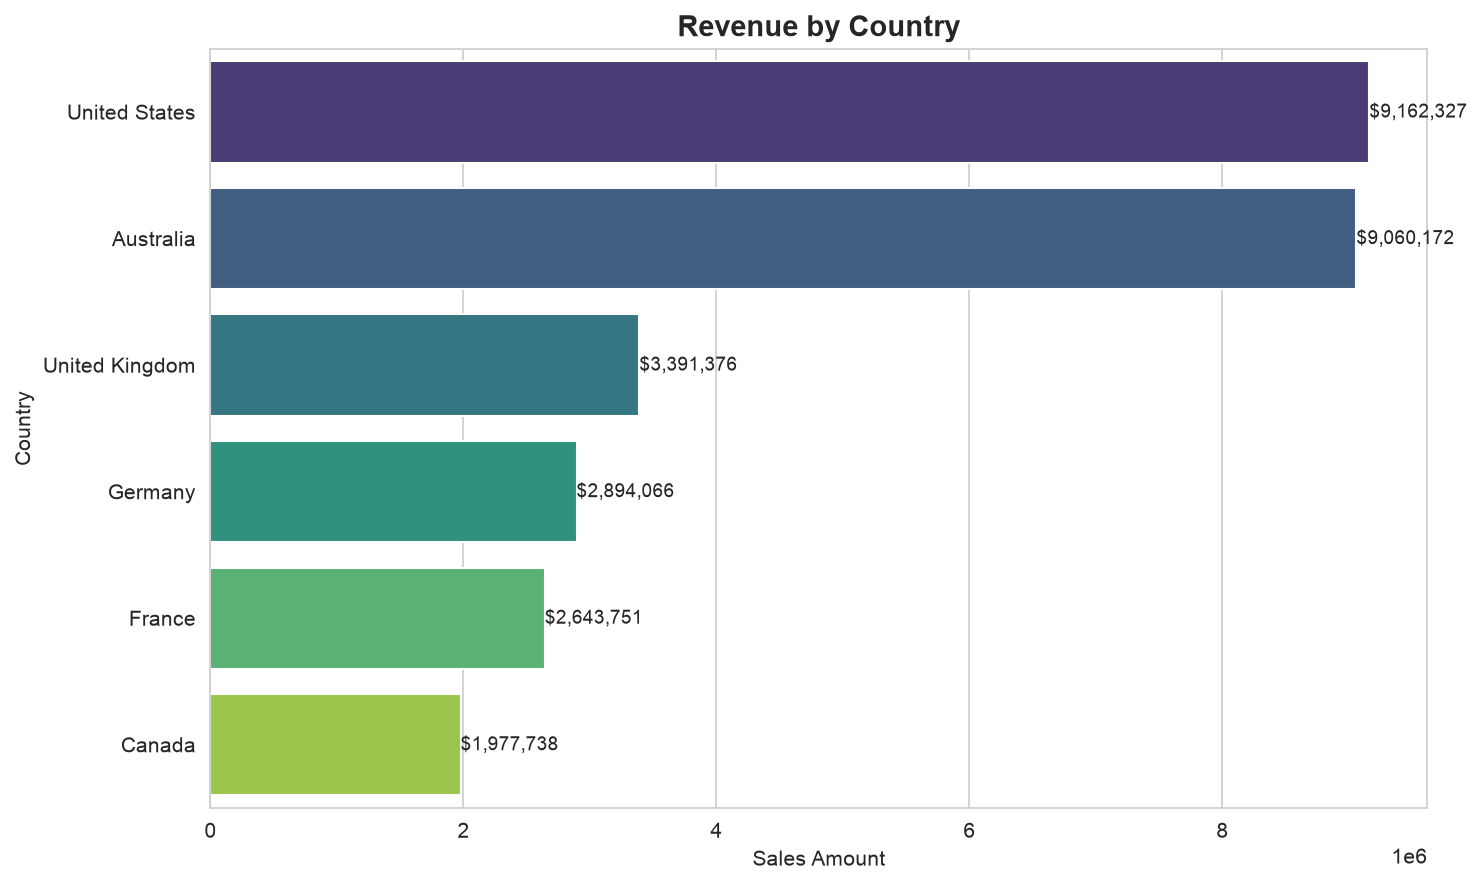

,country,sales_amount
5,United States,9162327
0,Australia,9060172
4,United Kingdom,3391376
3,Germany,2894066
2,France,2643751
1,Canada,1977738


In [3]:
country_revenue = fact.merge(customer[['customer_key', 'country']], on='customer_key', how='left')
country_revenue = country_revenue.groupby('country', as_index=False)['sales_amount'].sum()
country_revenue = country_revenue.sort_values('sales_amount', ascending=False).head(8)

plt.figure(figsize=(10, 6))
bar = sns.barplot(data=country_revenue, x='sales_amount', y='country', palette='viridis')
for patch in bar.patches:
    bar.annotate(f'${patch.get_width():,.0f}', (patch.get_width(), patch.get_y() + patch.get_height()/2), va='center', ha='left', fontsize=9)
plt.title('Revenue by Country', fontsize=14, fontweight='bold')
plt.xlabel('Sales Amount')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig(plots_dir / '01_revenue_by_country.png', dpi=200)
plt.show()
plt.close()
country_revenue

## 3. Which categories drive the most value?

This is the category contribution view. It helps identify where revenue is concentrated.

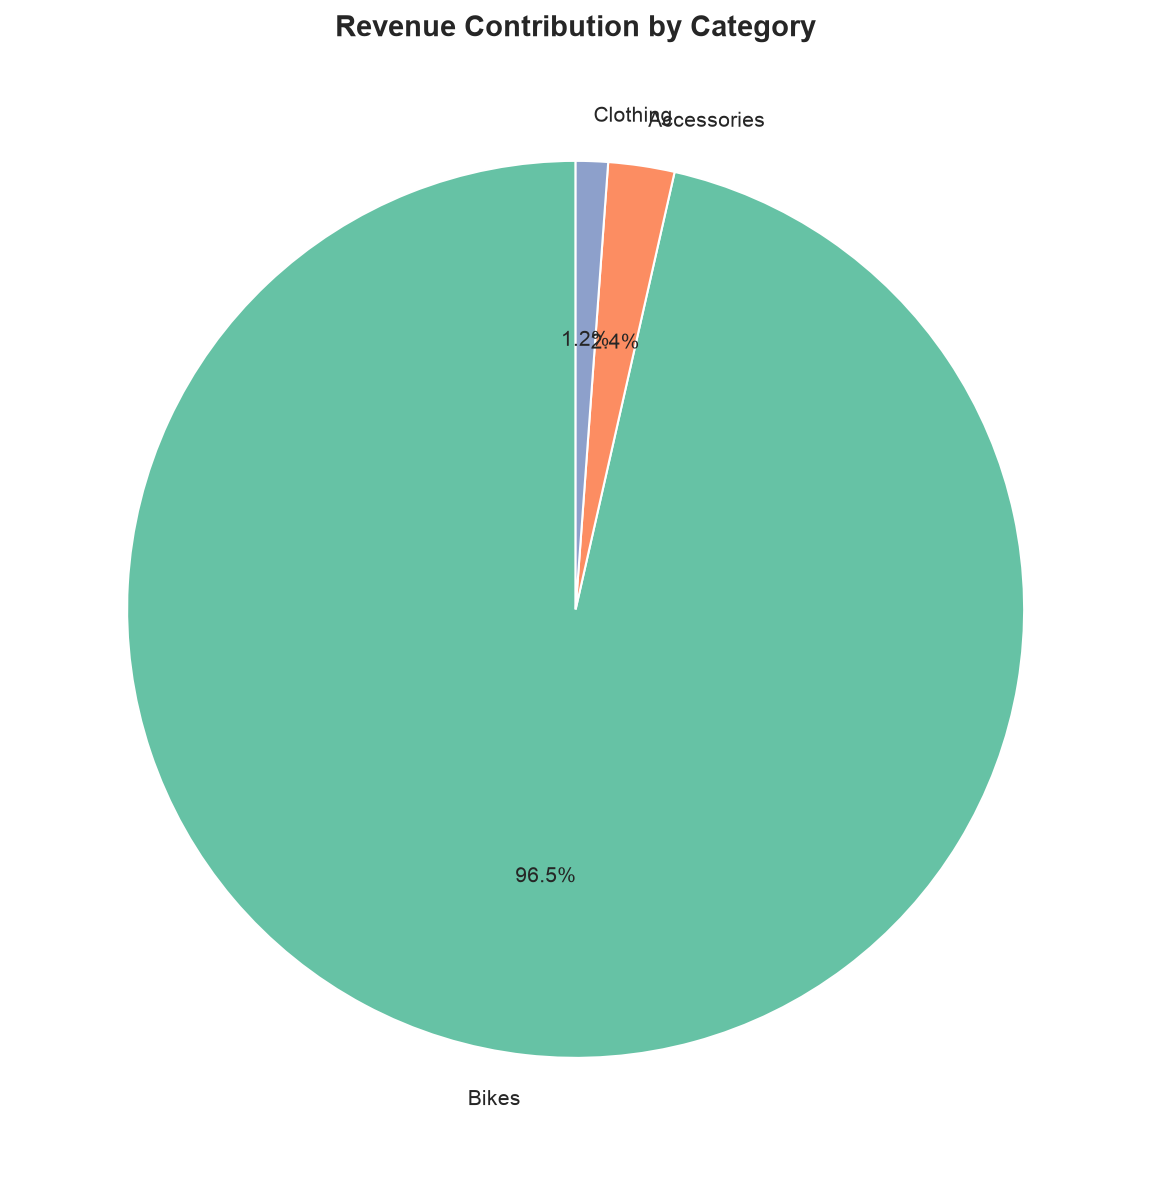

,category,sales_amount
1,Bikes,28316272
0,Accessories,700262
2,Clothing,339716


In [4]:
category_revenue = fact.merge(product[['product_key', 'category']], on='product_key', how='left')
category_revenue = category_revenue.groupby('category', as_index=False)['sales_amount'].sum()
category_revenue = category_revenue.sort_values('sales_amount', ascending=False)

plt.figure(figsize=(8, 8))
plt.pie(
    category_revenue['sales_amount'],
    labels=category_revenue['category'],
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set2', n_colors=len(category_revenue))
)
plt.title('Revenue Contribution by Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(plots_dir / '02_revenue_by_category.png', dpi=200)
plt.show()
plt.close()
category_revenue

## 4. How is sales trending over time?

This line chart helps identify the growth story and whether revenue is accelerating or slowing down.

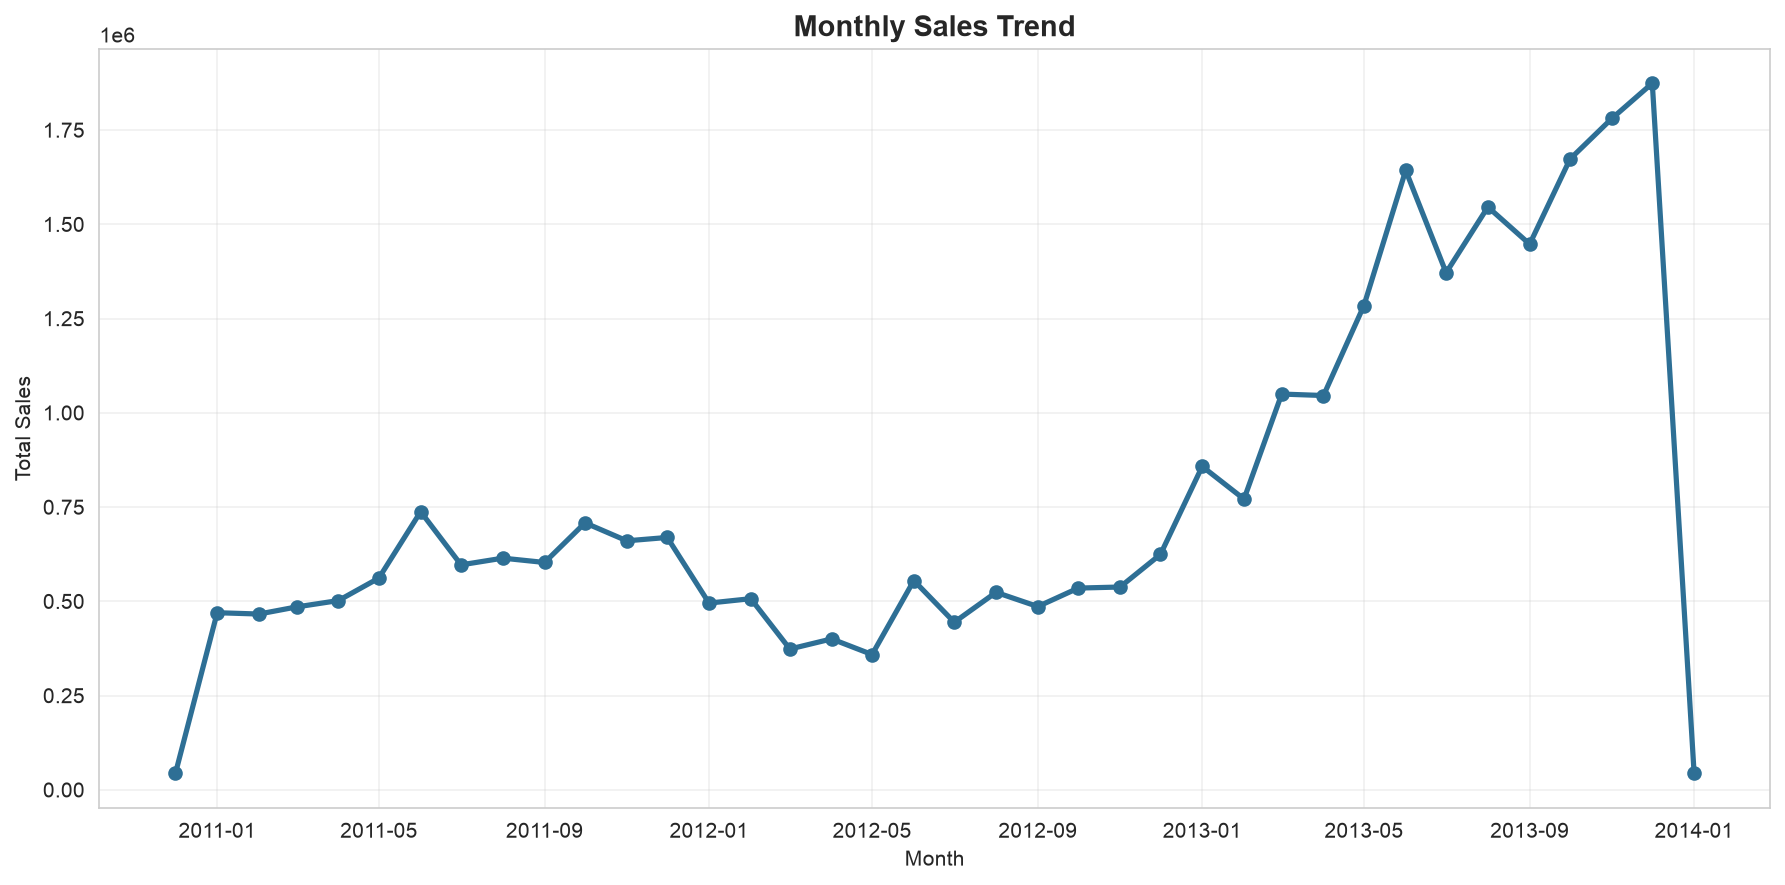

,month,total_sales,total_orders
0,2010-12-01,43419,14
1,2011-01-01,469795,144
2,2011-02-01,466307,144
3,2011-03-01,485165,150
4,2011-04-01,502042,157
5,2011-05-01,561647,174
6,2011-06-01,737793,230
7,2011-07-01,596710,188
8,2011-08-01,614516,193
9,2011-09-01,603047,185


In [5]:
monthly_sales = fact.groupby(fact['order_date'].dt.to_period('M').dt.to_timestamp(), as_index=False)
monthly_sales = monthly_sales.agg(total_sales=('sales_amount', 'sum'), total_orders=('order_number', 'nunique'))
monthly_sales = monthly_sales.rename(columns={'order_date': 'month'})
monthly_sales['month'] = pd.to_datetime(monthly_sales['month'])

plt.figure(figsize=(12, 6))
plt.plot(monthly_sales['month'], monthly_sales['total_sales'], marker='o', linewidth=2.5, color='#2E6F95')
plt.title('Monthly Sales Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(plots_dir / '03_monthly_sales_trend.png', dpi=200)
plt.show()
plt.close()
monthly_sales.head(12)

## 5. Which customer segments are we serving?

The customer segment view helps answer: are we acquiring a lot of new customers or building a loyal customer base?

/tmp/ipykernel_1754560/4167522445.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=customer_segment_counts.index, y=customer_segment_counts.values, palette='Blues')


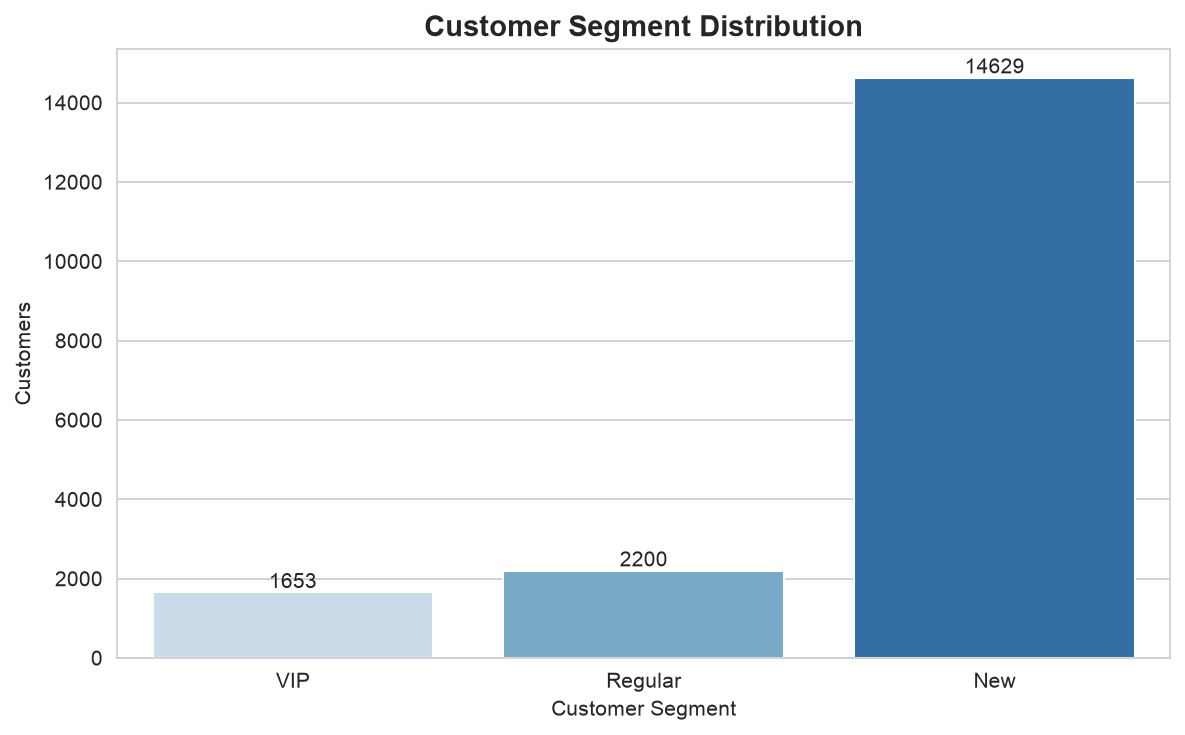

customer_segment
VIP         1653
Regular     2200
New        14629
Name: count, dtype: int64

In [6]:
customer_segment_counts = customer_report['customer_segment'].value_counts().reindex(['VIP', 'Regular', 'New'])

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=customer_segment_counts.index, y=customer_segment_counts.values, palette='Blues')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Customer Segment Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Customer Segment')
plt.ylabel('Customers')
plt.tight_layout()
plt.savefig(plots_dir / '04_customer_segments.png', dpi=200)
plt.show()
plt.close()
customer_segment_counts

## 6. What is the age profile of the customer base?

Age distribution helps us understand who is buying and whether the customer base is skewed toward a specific generation or demographic profile.

/tmp/ipykernel_1754560/3936049587.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=age_distribution.index, y=age_distribution.values, palette='magma')


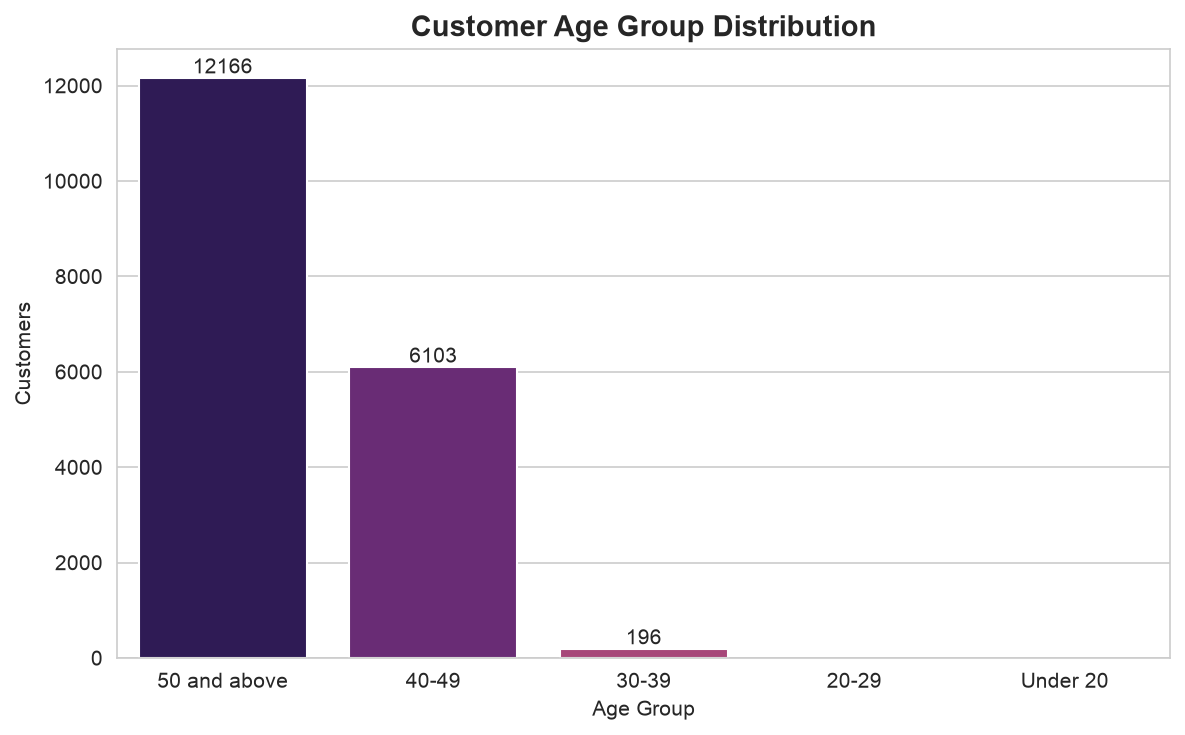

age_group
50 and above    12166.0
40-49            6103.0
30-39             196.0
20-29               NaN
Under 20            NaN
Name: count, dtype: float64

In [7]:
age_distribution = customer_report['age_group'].value_counts().reindex(['50 and above', '40-49', '30-39', '20-29', 'Under 20'])

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=age_distribution.index, y=age_distribution.values, palette='magma')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Customer Age Group Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Age Group')
plt.ylabel('Customers')
plt.tight_layout()
plt.savefig(plots_dir / '05_age_groups.png', dpi=200)
plt.show()
plt.close()
age_distribution

## 7. Which products are the strongest revenue drivers?

This view shows the top revenue-generating products and helps identify which items most strongly support financial performance.

/tmp/ipykernel_1754560/3786926925.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bar = sns.barplot(data=top_products, x='sales_amount', y='product_name', palette='rocket')


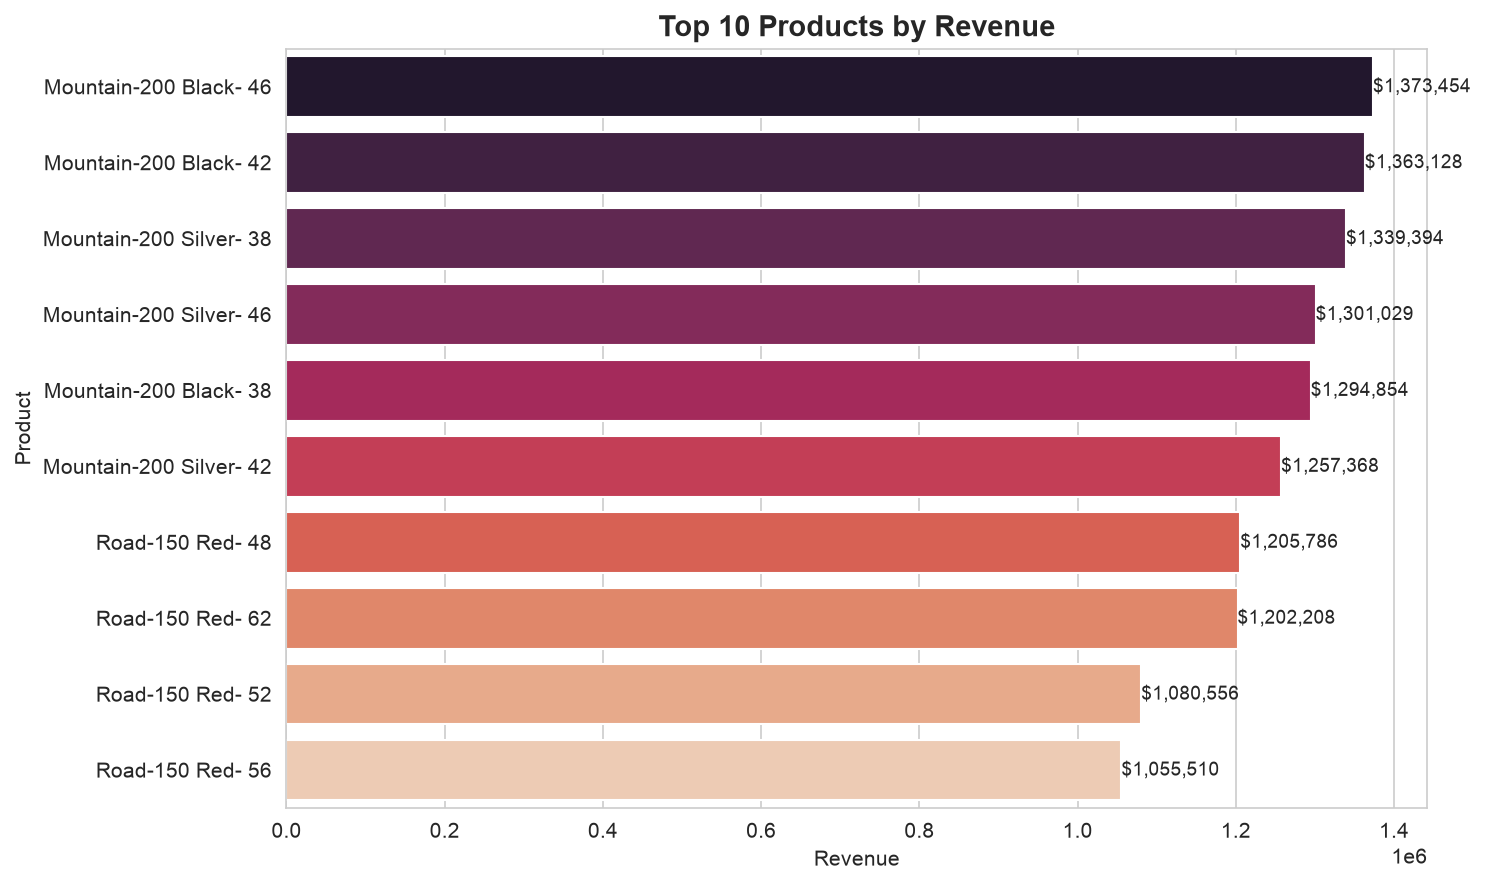

,product_name,sales_amount
34,Mountain-200 Black- 46,1373454
33,Mountain-200 Black- 42,1363128
35,Mountain-200 Silver- 38,1339394
37,Mountain-200 Silver- 46,1301029
32,Mountain-200 Black- 38,1294854
36,Mountain-200 Silver- 42,1257368
58,Road-150 Red- 48,1205786
61,Road-150 Red- 62,1202208
59,Road-150 Red- 52,1080556
60,Road-150 Red- 56,1055510


In [8]:
top_products = fact.merge(product[['product_key', 'product_name']], on='product_key', how='left')
top_products = top_products.groupby('product_name', as_index=False)['sales_amount'].sum()
top_products = top_products.sort_values('sales_amount', ascending=False).head(10)

plt.figure(figsize=(10, 6))
bar = sns.barplot(data=top_products, x='sales_amount', y='product_name', palette='rocket')
for patch in bar.patches:
    bar.annotate(f'${patch.get_width():,.0f}', (patch.get_width(), patch.get_y() + patch.get_height()/2), va='center', ha='left', fontsize=9)
plt.title('Top 10 Products by Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.tight_layout()
plt.savefig(plots_dir / '06_top_products_by_revenue.png', dpi=200)
plt.show()
plt.close()
top_products

## 8. Product segment performance

This chart helps classify products into performance buckets to reveal which items are strongest, moderate, or lagging behind.

/tmp/ipykernel_1754560/1561299250.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=product_segments.index, y=product_segments.values, palette='coolwarm')


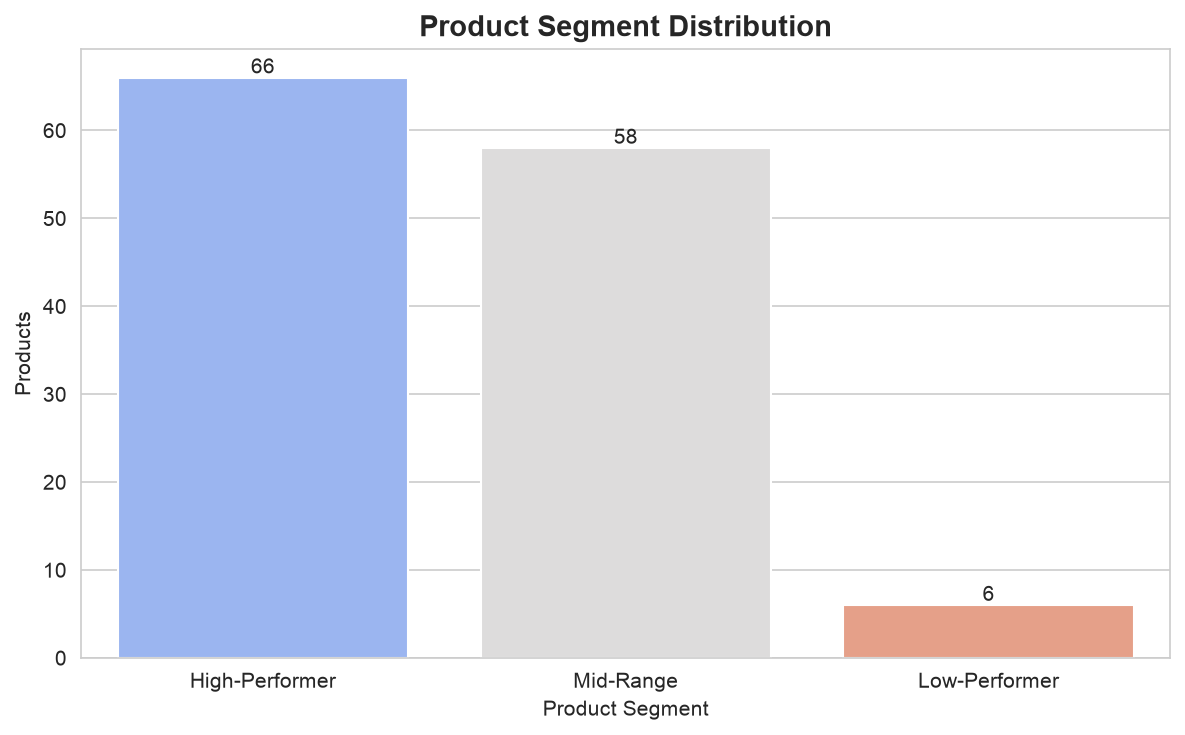

product_segment
High-Performer    66
Mid-Range         58
Low-Performer      6
Name: count, dtype: int64

In [9]:
product_segments = product_report['product_segment'].value_counts().reindex(['High-Performer', 'Mid-Range', 'Low-Performer'])

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=product_segments.index, y=product_segments.values, palette='coolwarm')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Product Segment Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Product Segment')
plt.ylabel('Products')
plt.tight_layout()
plt.savefig(plots_dir / '07_product_segments.png', dpi=200)
plt.show()
plt.close()
product_segments

## 9. Yearly sales performance

This helps summarize annual business performance and highlight the strongest years in revenue generation.

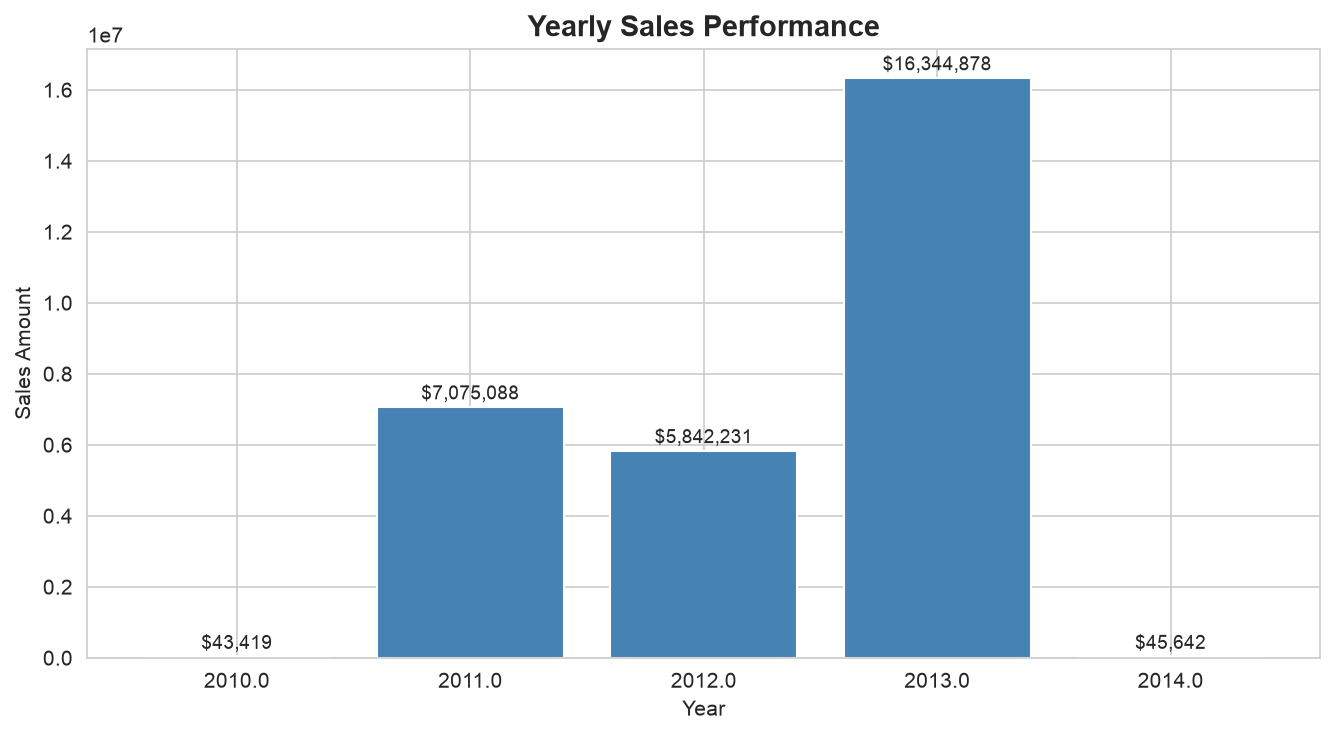

,year,sales_amount
0,2010.0,43419
1,2011.0,7075088
2,2012.0,5842231
3,2013.0,16344878
4,2014.0,45642


In [10]:
yearly_sales = fact.assign(year=fact['order_date'].dt.year)
yearly_sales = yearly_sales.groupby('year', as_index=False)['sales_amount'].sum().sort_values('year')

plt.figure(figsize=(9, 5))
bars = plt.bar(yearly_sales['year'].astype(str), yearly_sales['sales_amount'], color='steelblue')
for bar_obj in bars:
    height = bar_obj.get_height()
    plt.text(bar_obj.get_x() + bar_obj.get_width()/2, height + 100000, f'${height:,.0f}', ha='center', va='bottom', fontsize=9)
plt.title('Yearly Sales Performance', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Sales Amount')
plt.tight_layout()
plt.savefig(plots_dir / '08_yearly_sales_performance.png', dpi=200)
plt.show()
plt.close()
yearly_sales

# Final insight summary

The data shows that the business is strongly driven by a few important markets, categories, and products. The United States and Australia lead in revenue, Bikes dominate product mix, and the sales trend is positive overall.

The customer base is growing, but the business still has opportunity to deepen loyalty among regular and VIP customers. The product portfolio is mostly strong, though a small set of underperforming items may need pricing or positioning review.

These findings are presentation-ready and meaningful for business conversations, stakeholder updates, and interviews.